<a href="https://colab.research.google.com/github/dev-pa5an/windguard-offshore-wind-forecasting/blob/main/10_years_Analysis_Borssele_offshore_wind_farm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Borssele offshore wind farm**

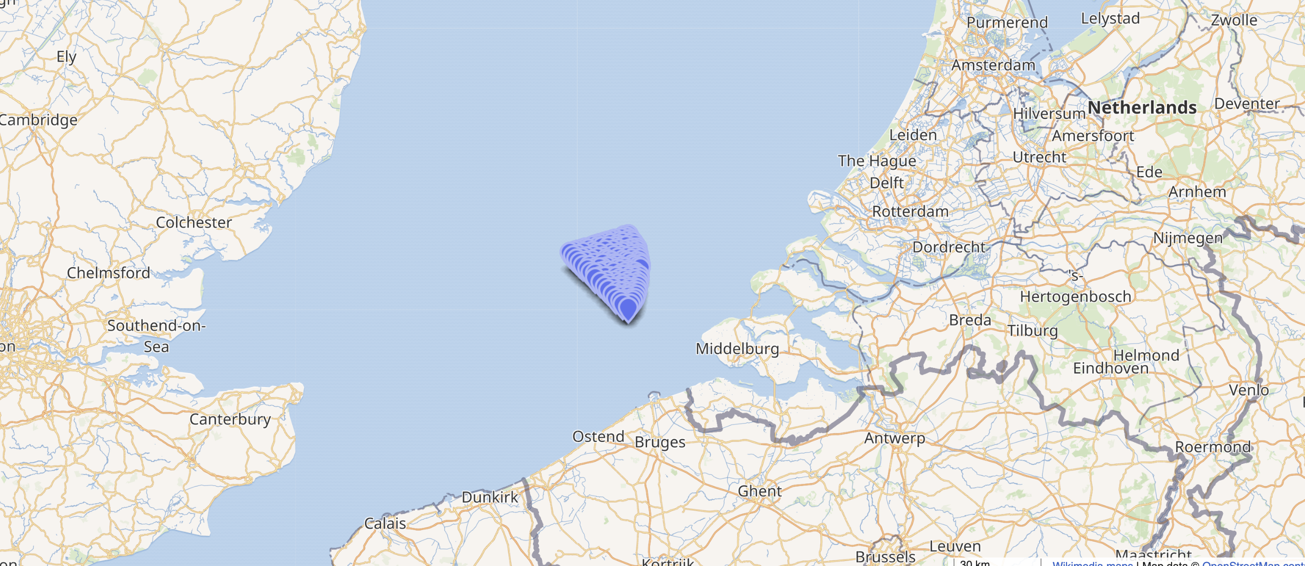

In [ ]:
from PIL import Image

img = Image.open("Borssele_Offshore_Wind_Farm.png")
width, height = img.size
resized_img = img.resize((int(width * 0.5), int(height * 0.5)))
resized_img.save("resized_image.png")
resized_img

| Parameter | Value |
| :--- | :--- |
| **Location** | Borssele offshore wind farm |
| **Coordinates** | 51.716667°N, 3.000000°E |
| **Target** | 100m hub height wind speed |
| **Horizon** | 24 hrs |
| **Problem Type** | Supervised Learning |
| **Task** | Regression |


$y_{t+24} = f(X_t)$

**Understanding the dataset before feature engineering**


**Dataset | reanalysis-era5-single-levels-timeseries**

| Variable | Meaning | Unit |
| :--- | :--- | :--- |
| `u100` | East-West wind component at 100 m | m/s |
| `v100` | North-South wind component at 100 m | m/s |
| `u10` | East-West wind component at 10 m | m/s |
| `v10` | North-South wind component at 10 m | m/s |
| `d2m` | Dew point temperature at 2 m | K |
| `t2m` | Air temperature at 2 m | K |
| `msl` | Mean sea-level pressure | Pa |
| `sp` | Surface pressure | Pa |
| `tcc` | Total cloud cover | 0–1 |
| `tp` | Total precipitation | m |


In [ ]:
!pip install -q ecmwf-datastores-client pyyaml itables xarray netCDF4 h5netcdf xgboost

In [ ]:
import yaml
import os
from google.colab import userdata

# Get your API key from Colab Secrets
key = userdata.get('CDS_API_KEY')

# CDS API URL
url = "https://cds.climate.copernicus.eu/api"

# Create credentials dictionary
credentials = {
    "url": url,
    "key": key
}

# Create configuration file in home directory
home_dir = os.path.expanduser("~")
config_path = os.path.join(home_dir, ".ecmwfdatastoresrc")

with open(config_path, "w") as f:
    yaml.safe_dump(credentials, f)

print("Your connection details have been saved!")

Your connection details have been saved!


In [ ]:
from ecmwf.datastores import Client

client = Client()
client.check_authentication()

{'id': 611655,
 'sub': '31127d54-f74c-424f-9b59-164401a233ce',
 'role': None,
 'email': 'pasanfernando24@gmail.com'}

In [ ]:
from ecmwf.datastores import Client

client = Client()

dataset = "reanalysis-era5-single-levels-timeseries"

request = {
    "variable": [
        "100m_u_component_of_wind",
        "100m_v_component_of_wind",
        "10m_u_component_of_wind",
        "10m_v_component_of_wind",
        "mean_sea_level_pressure",
        "surface_pressure",
        "2m_temperature",
        "2m_dewpoint_temperature",
        "instantaneous_10m_wind_gust",
        "total_cloud_cover",
        "total_precipitation"
    ],

    "date": [
        # "2016-01-01",
        # "2025-12-31"
        "2024-01-01",
        "2025-12-31"
    ],

    "location": {
        "longitude": 3.000000,
        "latitude": 51.716667
    },

    "data_format": "netcdf"
}

client.retrieve(
    dataset,
    request,
    target="era5_exploration_2025_storm.nc"
)

print("Download completed!")

235873d17572d402e3eaa3d46c0fbd3a.zip:   0%|          | 0.00/481k [00:00<?, ?B/s]

Download completed!


In [ ]:
import zipfile

# zip_path = "/content/era5_exploration_2016_2025.nc"
# extract_dir = "/content/era5_extracted_2016_2025"

zip_path = "/content/era5_exploration_2025_storm.nc"
extract_dir = "/content/era5_extracted_2025_storm"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    print("Files inside archive:", zip_ref.namelist())
    zip_ref.extractall(extract_dir)

Files inside archive: ['reanalysis-era5-single-levels-timeseries-sfcs55pu3qi.nc']


In [ ]:
import os

target = "/content/era5_exploration_2025_storm.nc"
extract_dir = "/content/era5_extracted_2025_storm"

if zipfile.is_zipfile(target):
    with zipfile.ZipFile(target, "r") as zip_ref:
        print("Files inside ZIP:", zip_ref.namelist())
        zip_ref.extractall(extract_dir)

    nc_files = [
        f for f in os.listdir(extract_dir)
        if f.endswith(".nc")
    ]

    nc_path = os.path.join(extract_dir, nc_files[0])

else:
    nc_path = target

print("NetCDF file:", nc_path)

Files inside ZIP: ['reanalysis-era5-single-levels-timeseries-sfcs55pu3qi.nc']
NetCDF file: /content/era5_extracted_2025_storm/reanalysis-era5-single-levels-timeseries-sfcs55pu3qi.nc


In [ ]:
import xarray as xr

#ds = xr.open_dataset(nc_path, engine="netcdf4")

ds25 = xr.open_dataset(nc_path, engine="netcdf4")

# print(ds)

In [ ]:
import pandas as pd
import numpy as np

#df = ds.to_dataframe().reset_index()

df25 = ds25.to_dataframe().reset_index()

# print(df.head())
# print(df.info())
# print(df.describe().T)

In [ ]:
import pandas as pd

# Assuming your DataFrame is named df or df_raw, and your timestamp column is 'time'
# If your timestamp is currently the DataFrame index, reset it first:
# df_to_save = df.reset_index()

# Export to CSV without saving the pandas default integer row index
df25.to_csv('df25.csv', index=False)

print("Successfully exported DataFrame to df26.csv!")

Successfully exported DataFrame to df26.csv!


In [ ]:
df["wind_speed_100m"] = np.sqrt(
    df["u100"]**2 + df["v100"]**2
)
df["wind_speed_10m"] = np.sqrt(
    df["u10"]**2 + df["v10"]**2
)

In [ ]:
df26["wind_speed_100m"] = np.sqrt(
    df26["u100"]**2 + df26["v100"]**2
)
df26["wind_speed_10m"] = np.sqrt(
    df26["u10"]**2 + df26["v10"]**2
)

In [ ]:
# 4. Multi-Horizon Training Function (h = 1 to 24 hours)
def train_24h_direct_models(df_features: pd.DataFrame, target_col: str = 'wind_speed_100m'):
    df_clean = df_features.dropna().copy()

    target_df = pd.DataFrame({
        f'target_h{h}': df_clean[target_col].shift(-h) for h in range(1, 25)
    }, index=df_clean.index)

    full_df = pd.concat([df_clean, target_df], axis=1).dropna()
    feature_cols = [c for c in df_clean.columns if not c.startswith('target_')]

    # Chronological Split
    train_mask = full_df.index < '2024-01-01'
    val_mask = (full_df.index >= '2024-01-01') & (full_df.index < '2025-01-01')

    X_train, X_val = full_df.loc[train_mask, feature_cols], full_df.loc[val_mask, feature_cols]

    models = {}
    params = {
        'boosting_type': 'gbdt',
        'learning_rate': 0.03,
        'num_leaves': 63,
        'feature_fraction': 0.8,
        'bagging_fraction': 0.8,
        'bagging_freq': 1,
        'objective': asymmetric_high_wind_loss,  # Custom training objective
        'metric': 'rmse',                        # FIX: Provide standard metric for early stopping evaluation
        'verbosity': -1
    }

    print("Training 24 independent direct models (t+1h to t+24h)...")
    for h in range(1, 25):
        y_train_h = full_df.loc[train_mask, f'target_h{h}']
        y_val_h = full_df.loc[val_mask, f'target_h{h}']

        dtrain = lgb.Dataset(X_train, label=y_train_h)
        dval = lgb.Dataset(X_val, label=y_val_h, reference=dtrain)

        model = lgb.train(
            params,
            dtrain,
            num_boost_round=1000,
            valid_sets=[dtrain, dval],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
        )
        models[f'h_{h}'] = model
        print(f"Horizon t+{h}h model trained.")

    return models

# 5. Execute Training and Save Artifacts
models = train_24h_direct_models(df_features, target_col='wind_speed_100m')

output_dir = Path("./models/wind_forecast_24h")
output_dir.mkdir(parents=True, exist_ok=True)
for horizon, model in models.items():
    model.save_model(str(output_dir / f"lgb_model_{horizon}.txt"))

print("All 24 models successfully trained and saved to disk!")

Training 24 independent direct models (t+1h to t+24h)...
Horizon t+1h model trained.
Horizon t+2h model trained.
Horizon t+3h model trained.
Horizon t+4h model trained.
Horizon t+5h model trained.
Horizon t+6h model trained.
Horizon t+7h model trained.
Horizon t+8h model trained.
Horizon t+9h model trained.
Horizon t+10h model trained.
Horizon t+11h model trained.
Horizon t+12h model trained.
Horizon t+13h model trained.
Horizon t+14h model trained.
Horizon t+15h model trained.
Horizon t+16h model trained.
Horizon t+17h model trained.
Horizon t+18h model trained.
Horizon t+19h model trained.
Horizon t+20h model trained.
Horizon t+21h model trained.
Horizon t+22h model trained.
Horizon t+23h model trained.
Horizon t+24h model trained.
All 24 models successfully trained and saved to disk!


In [ ]:
import numpy as np
import pandas as pd

# 1. Define the function first
def build_era5_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Vector Shear & Magnitudes
    df['shear_100_10'] = df['wind_speed_100m'] - df['wind_speed_10m']
    df['vec_shear'] = np.sqrt((df['u100'] - df['u10'])**2 + (df['v100'] - df['v10'])**2)

    # Thermodynamic & Physical Proxies
    R_spec = 287.058  # Specific gas constant for dry air J/(kg·K)
    df['air_density'] = df['sp'] / (R_spec * df['t2m'])
    df['dew_point_depression'] = df['t2m'] - df['d2m']

    # Synoptic Pressure Tendencies
    df['msl_diff_1h'] = df['msl'].diff(1)
    df['msl_diff_3h'] = df['msl'].diff(3)
    df['msl_diff_6h'] = df['msl'].diff(6)

    # Cyclic Time Features
    hour = df.index.hour
    day_of_year = df.index.dayofyear
    df['hour_sin'] = np.sin(2 * np.pi * hour / 24.0)
    df['hour_cos'] = np.cos(2 * np.pi * hour / 24.0)
    df['doy_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
    df['doy_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)

    # Lags and Rolling Window Statistics
    base_cols = [
        'wind_speed_100m', 'shear_100_10', 'msl_diff_3h',
        'air_density', 'u100', 'v100', 'tcc', 'tp'
    ]

    lag_features = {}
    for col in base_cols:
        for lag in [1, 2, 3, 6, 12, 24]:
            lag_features[f'{col}_lag_{lag}h'] = df[col].shift(lag)

    for col in ['wind_speed_100m', 'msl', 'shear_100_10']:
        for window in [6, 12, 24]:
            lag_features[f'{col}_roll_mean_{window}h'] = df[col].shift(1).rolling(window).mean()
            lag_features[f'{col}_roll_std_{window}h'] = df[col].shift(1).rolling(window).std()
            lag_features[f'{col}_roll_max_{window}h'] = df[col].shift(1).rolling(window).max()

    df_lags = pd.DataFrame(lag_features, index=df.index)
    return pd.concat([df, df_lags], axis=1)

# 2. Ensure time is properly set as the DatetimeIndex
time_col = 'time' if 'time' in df.columns else 'valid_time'
if time_col in df.columns and not isinstance(df.index, pd.DatetimeIndex):
    df[time_col] = pd.to_datetime(df[time_col])
    df = df.set_index(time_col)

df = df.sort_index()

# 3. Run it to generate df_features
print("Engineering features...")
df_features = build_era5_features(df)
print("Success! df_features is now ready.")

Engineering features...
Success! df_features is now ready.


In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from pathlib import Path
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Load saved models from disk
model_dir = Path("./models/wind_forecast_24h")
models = {}
for h in range(1, 25):
    model_path = model_dir / f"lgb_model_h_{h}.txt"
    models[f'h_{h}'] = lgb.Booster(model_file=str(model_path))

# 2. Prepare Test Data (assuming df_features is already engineered)
df_clean = df_features.dropna().copy()
target_col = 'wind_speed_100m'

# Build test target matrix
target_df = pd.DataFrame({
    f'target_h{h}': df_clean[target_col].shift(-h) for h in range(1, 25)
}, index=df_clean.index)

full_df = pd.concat([df_clean, target_df], axis=1).dropna()
feature_cols = [c for c in df_clean.columns if not c.startswith('target_')]

# Filter for Test Set (e.g., Year 2025)
test_mask = full_df.index >= '2025-01-01'
X_test = full_df.loc[test_mask, feature_cols]

# 3. Generate Predictions Across All Test Timestamps & Horizons
print("Evaluating models on the test set...")
results = []

for timestamp, row in X_test.iterrows():
    X_row = pd.DataFrame([row], columns=feature_cols)
    preds = [models[f'h_{h}'].predict(X_row)[0] for h in range(1, 25)]

    actuals = [full_df.loc[timestamp, f'target_h{h}'] for h in range(1, 25)]

    results.append({
        'timestamp': timestamp,
        'pred': preds,
        'actual': actuals
    })

# 4. Compute Metrics per Horizon
horizon_metrics = []
for h_idx, h in enumerate(range(1, 25)):
    y_pred = [r['pred'][h_idx] for r in results]
    y_act = [r['actual'][h_idx] for r in results]

    rmse = np.sqrt(mean_squared_error(y_act, y_pred))
    mae = mean_absolute_error(y_act, y_pred)

    horizon_metrics.append({'horizon': f'+{h}h', 'RMSE': rmse, 'MAE': mae})

metrics_df = pd.DataFrame(horizon_metrics)
print("\n--- Test Performance Summary (First 6 Hours) ---")
print(metrics_df.head(6))

Evaluating models on the test set...

--- Test Performance Summary (First 6 Hours) ---
  horizon      RMSE       MAE
0     +1h  0.575565  0.401035
1     +2h  1.046417  0.756474
2     +3h  1.415475  1.045134
3     +4h  1.711112  1.279461
4     +5h  1.968187  1.484906
5     +6h  2.216410  1.689365


In [ ]:
print(metrics_df.tail(6))

   horizon      RMSE       MAE
18    +19h  3.488165  2.776832
19    +20h  3.526938  2.806867
20    +21h  3.562649  2.841546
21    +22h  3.600753  2.875515
22    +23h  3.634246  2.903289
23    +24h  3.661213  2.921361


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Ensure we have the results list from the previous evaluation step,
# or re-run a fast evaluation loop filtered for extreme events (> 15 m/s)

extreme_metrics = []

for h_idx, h in enumerate(range(1, 25)):
    # Extract predictions and actuals for horizon h
    preds_h = np.array([r['pred'][h_idx] for r in results])
    acts_h = np.array([r['actual'][h_idx] for r in results])

    # Filter strictly for extreme wind events (> 15 m/s)
    mask = acts_h > 15.0

    if mask.sum() > 0:
        act_ext = acts_h[mask]
        pred_ext = preds_h[mask]

        rmse_ext = np.sqrt(mean_squared_error(act_ext, pred_ext))
        mae_ext = mean_absolute_error(act_ext, pred_ext)

        # Mean Bias: positive means over-forecasting, negative means under-forecasting
        bias_ext = np.mean(pred_ext - act_ext)

        extreme_metrics.append({
            'horizon': f'+{h}h',
            'storm_sample_count': mask.sum(),
            'RMSE_extreme': rmse_ext,
            'MAE_extreme': mae_ext,
            'Bias_extreme': bias_ext
        })
    else:
        extreme_metrics.append({
            'horizon': f'+{h}h',
            'storm_sample_count': 0,
            'RMSE_extreme': np.nan,
            'MAE_extreme': np.nan,
            'Bias_extreme': np.nan
        })

df_extreme = pd.DataFrame(extreme_metrics)

print("--- Extreme Wind Performance (> 15 m/s) ---")
print(df_extreme.head(12))

--- Extreme Wind Performance (> 15 m/s) ---
   horizon  storm_sample_count  RMSE_extreme  MAE_extreme  Bias_extreme
0      +1h                 678      0.774420     0.509296     -0.032692
1      +2h                 677      1.442375     0.901477     -0.308042
2      +3h                 676      1.931813     1.291456     -0.702650
3      +4h                 675      2.269758     1.583569     -1.103476
4      +5h                 674      2.570057     1.910822     -1.509789
5      +6h                 673      2.975775     2.287559     -2.085810
6      +7h                 672      3.436032     2.777860     -2.654751
7      +8h                 671      3.782864     3.114762     -3.025514
8      +9h                 670      4.091529     3.459912     -3.404088
9     +10h                 669      4.388055     3.776623     -3.725499
10    +11h                 668      4.754518     4.178919     -4.146393
11    +12h                 667      5.058765     4.514017     -4.500102


#Inference

In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from pathlib import Path

# 1. Load the 24 saved models from disk
model_dir = Path("./models/wind_forecast_24h")
models = {}
print("Loading saved models...")
for h in range(1, 25):
    model_path = model_dir / f"lgb_model_h_{h}.txt"
    if model_path.exists():
        models[f'h_{h}'] = lgb.Booster(model_file=str(model_path))
    else:
        raise FileNotFoundError(f"Could not find model file for horizon +{h}h at {model_path}")

print(f"Successfully loaded {len(models)} horizon models.")

# 2. Define the Inference Function
def generate_24h_forecast(current_timestamp, df_features, models_dict):
    """
    Generates a 24-hour wind speed forecast starting from a specific timestamp.
    """
    if current_timestamp not in df_features.index:
        raise ValueError(f"Timestamp {current_timestamp} not found in df_features index.")

    # Extract feature columns (excluding any target columns if present)
    feature_cols = [c for c in df_features.columns if not c.startswith('target_')]
    X_current = df_features.loc[[current_timestamp], feature_cols]

    forecast_curve = {}
    for h in range(1, 25):
        model = models_dict[f'h_{h}']
        pred_speed = model.predict(X_current)[0]

        # Clamp negative values to 0.0 since wind speed cannot be negative
        forecast_curve[f'+{h}h'] = max(0.0, pred_speed)

    return pd.Series(forecast_curve, name=f"Forecast_Started_{current_timestamp}")

# 3. Test the Inference Function on a Sample Timestamp
# Pick any timestamp available in your engineered feature dataset
sample_timestamp = df_features.index[100]

print(f"\nGenerating 24-hour forecast for: {sample_timestamp}")
forecast_series = generate_24h_forecast(sample_timestamp, df_features, models)

print("\n--- Predicted Wind Speed Curve (m/s) ---")
print(forecast_series)

In [ ]:
# Extract feature columns for a sample timestamp
feature_cols = [c for c in df_features.columns if not c.startswith('target_')]
sample_timestamp = df_features.index[100]

# Get the exact input row as a pandas Series
input_vector = df_features.loc[sample_timestamp, feature_cols]

print(f"Total number of features in input vector: {len(input_vector)}")
print("\n--- Sample of the Model Input Vector ---")
print(input_vector.head(20))  # Displaying the first 20 features

Total number of features in input vector: 100

--- Sample of the Model Input Vector ---
u100                    8.801575e-01
v100                    1.096710e+01
u10                     4.400635e-01
v10                     9.606644e+00
d2m                     2.789791e+02
t2m                     2.810309e+02
msl                     9.861800e+04
sp                      9.862902e+04
tcc                     9.101562e-01
tp                      9.536743e-07
latitude                5.175000e+01
longitude               3.000000e+00
wind_speed_100m         1.100236e+01
wind_speed_10m          9.616718e+00
shear_100_10            1.385645e+00
vec_shear               1.429870e+00
air_density             1.222591e+00
dew_point_depression    2.051758e+00
msl_diff_1h            -1.706250e+01
msl_diff_3h             1.262500e+01
Name: 2016-01-05 04:00:00, dtype: float64


In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from pathlib import Path

def get_24h_wind_forecast(start_timestamp_str: str, raw_df: pd.DataFrame, model_dir: str = "./models/wind_forecast_24h") -> pd.Series:
    """
    Given any target timestamp string, this function:
    1. Slices the historical data up to that exact moment to compute rolling lags safely.
    2. Runs your feature engineering pipeline automatically.
    3. Loads your 24 saved models and predicts the next 24 hours of wind speed.
    """
    target_dt = pd.to_datetime(start_timestamp_str)

    # 1. Ensure the raw dataframe has a proper DatetimeIndex
    time_col = 'time' if 'time' in raw_df.columns else 'valid_time'
    df_temp = raw_df.copy()
    if time_col in df_temp.columns and not isinstance(df_temp.index, pd.DatetimeIndex):
        df_temp[time_col] = pd.to_datetime(df_temp[time_col])
        df_temp = df_temp.set_index(time_col)
    df_temp = df_temp.sort_index()

    # 2. Check if the timestamp exists in your data
    if target_dt not in df_temp.index:
        raise ValueError(f"Timestamp '{start_timestamp_str}' not found in the dataset index.")

    # 3. Slice data up to the target timestamp (to ensure rolling window/lag history is correct)
    # We take everything up to target_dt (we need past 24h for lag features)
    historical_slice = df_temp.loc[:target_dt]
    if len(historical_slice) < 25:
        raise ValueError(f"Not enough historical context before {start_timestamp_str} to compute 24h lags.")

    # 4. Apply your feature engineering function
    features_slice = build_era5_features(historical_slice)

    # Extract the exact feature row for the requested timestamp
    feature_cols = [c for c in features_slice.columns if not c.startswith('target_')]
    X_current = features_slice.loc[[target_dt], feature_cols]

    # 5. Load the 24 models from disk
    models = {}
    path = Path(model_dir)
    for h in range(1, 25):
        model_path = path / f"lgb_model_h_{h}.txt"
        if not model_path.exists():
            raise FileNotFoundError(f"Missing model file for horizon +{h}h at {model_path}")
        models[f'h_{h}'] = lgb.Booster(model_file=str(model_path))

    # 6. Generate the 24-hour forecast curve
    forecast_curve = {}
    # Calculate actual future timestamps for clear labeling
    future_timestamps = pd.date_range(start=target_dt + pd.Timedelta(hours=1), periods=24, freq='h')

    for idx, h in enumerate(range(1, 25)):
        pred_speed = models[f'h_{h}'].predict(X_current)[0]
        # Wind speeds cannot be physically negative; clamp at 0.0
        forecast_curve[str(future_timestamps[idx])] = max(0.0, pred_speed)

    return pd.Series(forecast_curve, name=f"Wind_Forecast_From_{start_timestamp_str}")

# ==========================================
# Example of how you will use it:
# ==========================================
user_query_time = '2016-01-05 04:00:00'
#
# # Pass your original raw dataframe (`df`) and the target string
result_forecast = get_24h_wind_forecast(user_query_time, df)
print(result_forecast)

2016-01-05 05:00:00    11.082980
2016-01-05 06:00:00    11.174852
2016-01-05 07:00:00    11.370545
2016-01-05 08:00:00    11.798689
2016-01-05 09:00:00    11.574715
2016-01-05 10:00:00    11.665276
2016-01-05 11:00:00    11.910378
2016-01-05 12:00:00    11.797112
2016-01-05 13:00:00    11.828896
2016-01-05 14:00:00    11.821654
2016-01-05 15:00:00    11.901818
2016-01-05 16:00:00    12.053440
2016-01-05 17:00:00    12.043699
2016-01-05 18:00:00    11.904553
2016-01-05 19:00:00    11.547167
2016-01-05 20:00:00    11.431459
2016-01-05 21:00:00    11.519679
2016-01-05 22:00:00    11.104920
2016-01-05 23:00:00    11.455693
2016-01-06 00:00:00    10.842240
2016-01-06 01:00:00    11.248430
2016-01-06 02:00:00    10.792661
2016-01-06 03:00:00    10.886197
2016-01-06 04:00:00    10.165788
Name: Wind_Forecast_From_2016-01-05 04:00:00, dtype: float64


In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from pathlib import Path

# 1. Prepare df26: Ensure proper DatetimeIndex
time_col = 'time' if 'time' in df26.columns else 'valid_time'
if time_col in df26.columns and not isinstance(df26.index, pd.DatetimeIndex):
    df26[time_col] = pd.to_datetime(df26[time_col])
    df26 = df26.set_index(time_col)
df26 = df26.sort_index()

# 2. Run feature engineering on df26 so lags/rolling features exist
print("Engineering features for df26...")
df26_features = build_era5_features(df26)

# 3. Select your target start timestamp in March 2026
# (Ensure this timestamp exists in df26 and has at least 24h of prior data for lags)
target_time = '2026-03-07 00:00:00'

# 4. Generate the 24-hour forecast using the saved models
def predict_from_df(start_timestamp_str, features_df, model_dir="./models/wind_forecast_24h"):
    target_dt = pd.to_datetime(start_timestamp_str)
    if target_dt not in features_df.index:
        raise ValueError(f"Timestamp {start_timestamp_str} not found in df26_features index.")

    feature_cols = [c for c in features_df.columns if not c.startswith('target_')]
    X_current = features_df.loc[[target_dt], feature_cols]

    models = {}
    path = Path(model_dir)
    for h in range(1, 25):
        model_path = path / f"lgb_model_h_{h}.txt"
        models[f'h_{h}'] = lgb.Booster(model_file=str(model_path))

    forecast_curve = {}
    future_timestamps = pd.date_range(start=target_dt + pd.Timedelta(hours=1), periods=24, freq='h')

    for idx, h in enumerate(range(1, 25)):
        pred_speed = models[f'h_{h}'].predict(X_current)[0]
        forecast_curve[future_timestamps[idx]] = max(0.0, pred_speed)

    return pd.Series(forecast_curve, name="Predicted")

# 5. Get Actuals from df26 for that same 24-hour window
def get_actuals_from_df(start_timestamp_str, raw_df, target_col='wind_speed_100m'):
    target_dt = pd.to_datetime(start_timestamp_str)
    future_timestamps = pd.date_range(start=target_dt + pd.Timedelta(hours=1), periods=24, freq='h')

    actuals = raw_df.loc[future_timestamps, target_col]
    actuals.name = "Actual"
    return actuals

# 6. Execute and display comparison table
forecast_series = predict_from_df(target_time, df26_features)
actual_series = get_actuals_from_df(target_time, df26)

comparison_df = pd.DataFrame({
    'Predicted (m/s) absc': forecast_series.values,
    'Actual (m/s)': actual_series.values
}, index=forecast_series.index)

print(f"\n--- 24-Hour Forecast vs Actual Comparison Starting From {target_time} ---")
print(comparison_df)

Engineering features for df26...

--- 24-Hour Forecast vs Actual Comparison Starting From 2026-03-07 00:00:00 ---
                     Predicted (m/s) absc  Actual (m/s)
2026-03-07 01:00:00              5.568092      5.821115
2026-03-07 02:00:00              5.511728      5.621536
2026-03-07 03:00:00              5.309498      5.436692
2026-03-07 04:00:00              5.552129      5.513675
2026-03-07 05:00:00              5.378710      5.824623
2026-03-07 06:00:00              4.840719      6.066134
2026-03-07 07:00:00              4.936298      6.451685
2026-03-07 08:00:00              5.028028      6.760785
2026-03-07 09:00:00              4.983823      6.680027
2026-03-07 10:00:00              5.033348      5.638199
2026-03-07 11:00:00              4.831825      5.765854
2026-03-07 12:00:00              5.068799      5.999785
2026-03-07 13:00:00              5.266007      6.484437
2026-03-07 14:00:00              5.521783      7.078885
2026-03-07 15:00:00              6.020877     

In [ ]:
import shutil
from pathlib import Path

# Define the source model directory and output zip path
model_dir = Path("./models/wind_forecast_24h")
output_zip_path = Path("./models/wind_forecast_24h.zip")

if model_dir.exists():
    # Create the zip archive
    shutil.make_archive(
        base_name=str(output_zip_path.with_suffix('')), # omits .zip suffix for make_archive
        format='zip',
        root_dir=str(model_dir)
    )
    print(f"Successfully created archive: {output_zip_path.absolute()}")
else:
    print(f"Directory not found at {model_dir.absolute()}. Check your path.")

Successfully created archive: /content/models/wind_forecast_24h.zip


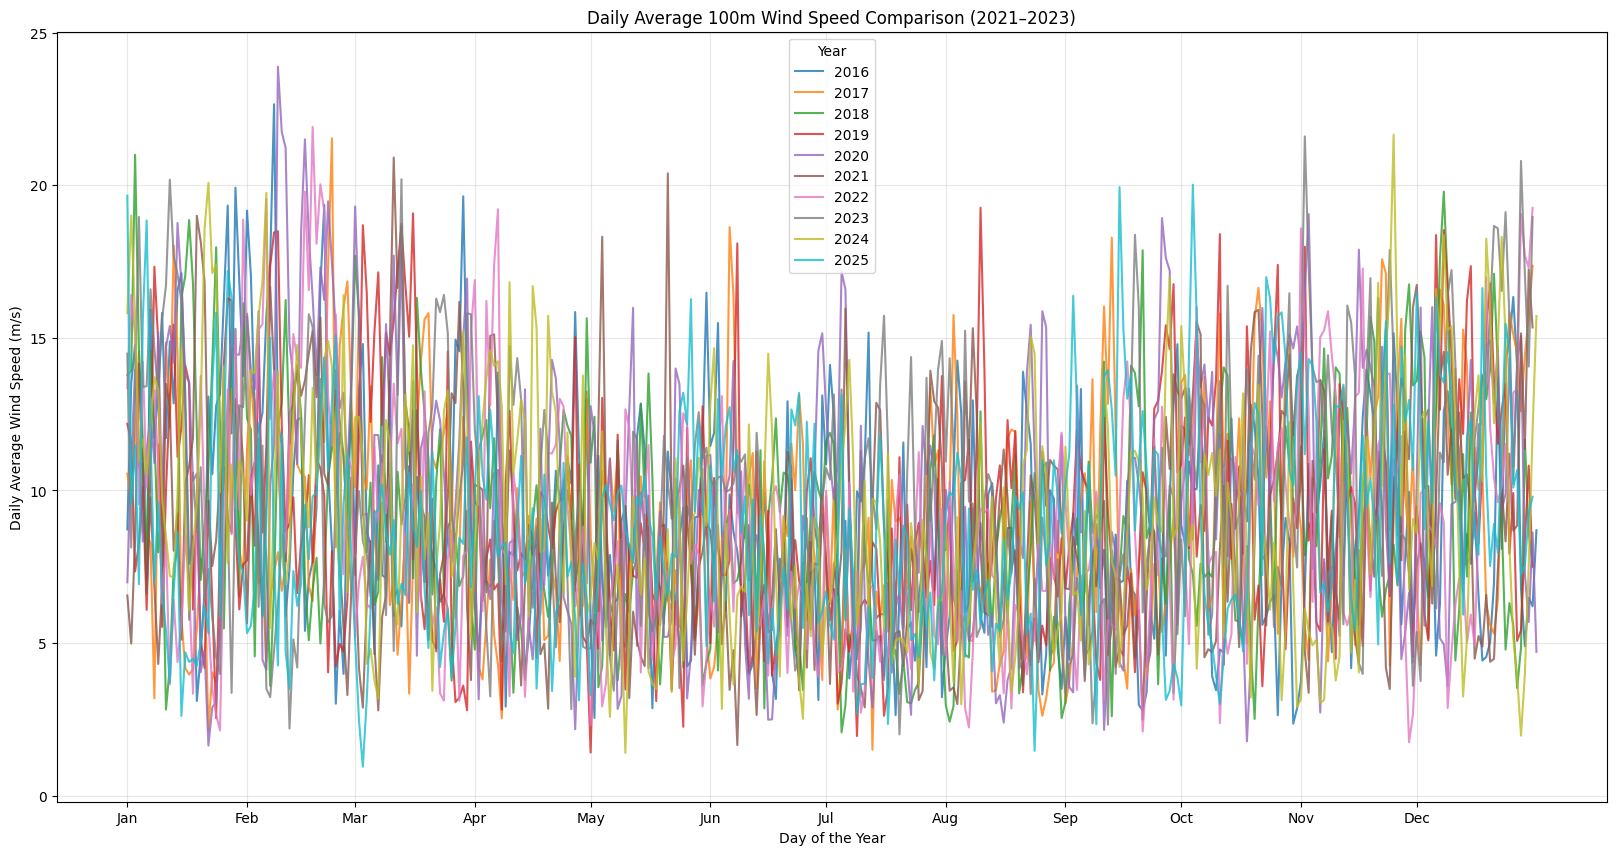

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20, 10))

for year in [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]:

    yearly_data = daily_wind[
        daily_wind["year"] == year
    ]

    plt.plot(
        yearly_data["day_of_year"],
        yearly_data["wind_speed_100m"],
        label=str(year),
        alpha=0.8
    )

plt.xlabel("Day of the Year")
plt.ylabel("Daily Average Wind Speed (m/s)")

plt.title(
    "Daily Average 100m Wind Speed Comparison (2021–2023)"
)

plt.xticks(
    [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.show()

# Let's plot the daily maximum values for each day in 2021,2022, 2023

In [ ]:
df = df[
    ~(
        (df["valid_time"].dt.month == 2) &
        (df["valid_time"].dt.day == 29)
    )
].copy()

In [ ]:
df["date"] = df["valid_time"].dt.date
df["year"] = df["valid_time"].dt.year

daily_max_wind = (
    df.groupby(["year", "date"])["wind_speed_100m"]
    .max()
    .reset_index()
)

daily_max_wind["date"] = pd.to_datetime(
    daily_max_wind["date"]
)

daily_max_wind["day_of_year"] = (
    daily_max_wind["date"].dt.dayofyear
)

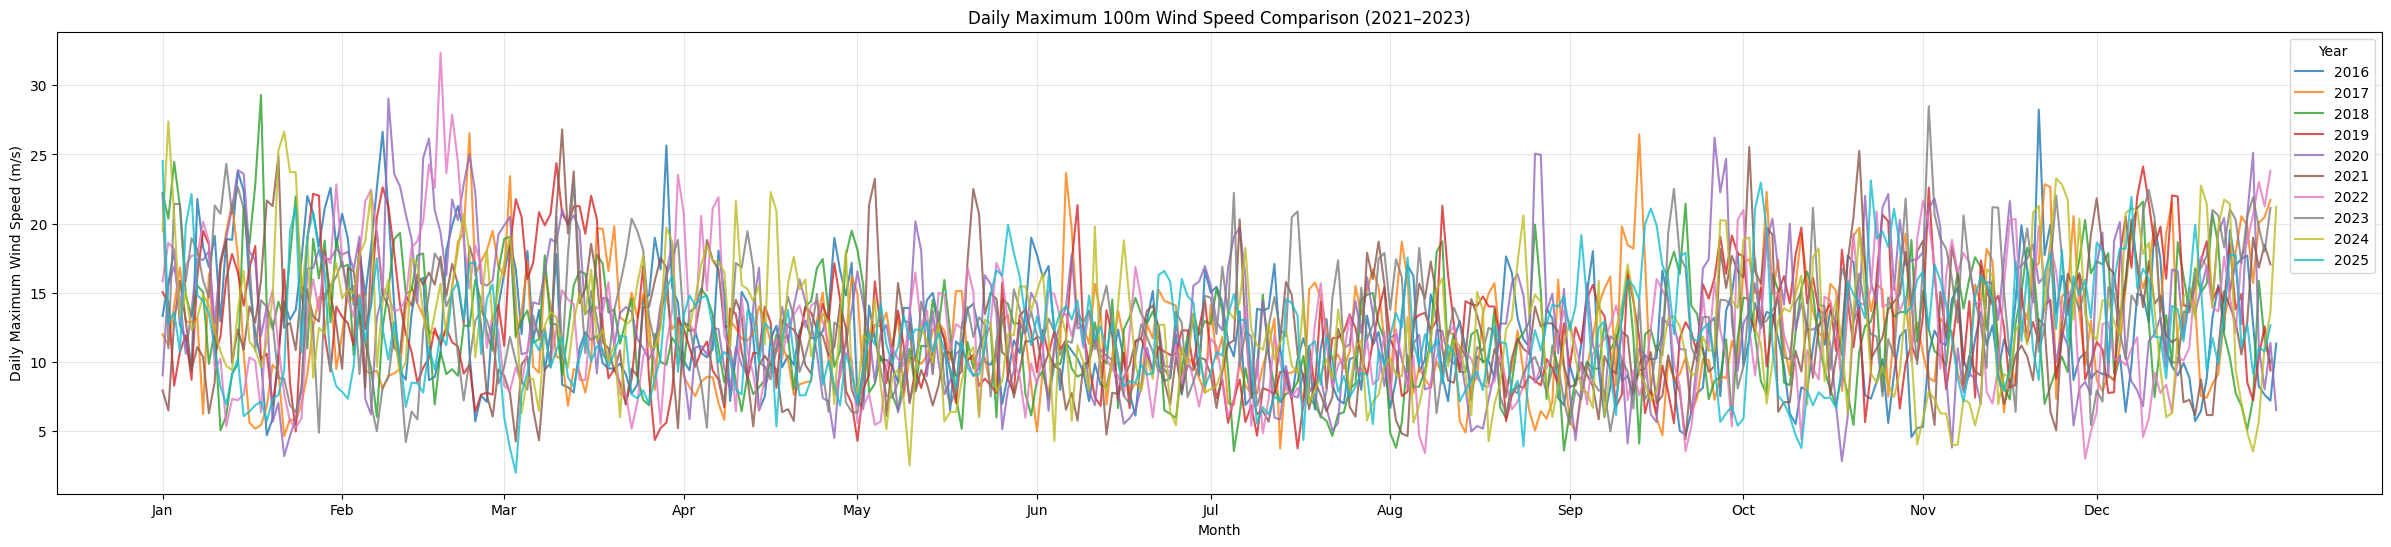

In [ ]:
plt.figure(figsize=(30, 6))

for year in [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]:

    yearly_data = daily_max_wind[
        daily_max_wind["year"] == year
    ]

    plt.plot(
        yearly_data["day_of_year"],
        yearly_data["wind_speed_100m"],
        label=str(year),
        alpha=0.8
    )

plt.xlabel("Month")
plt.ylabel("Daily Maximum Wind Speed (m/s)")

plt.title(
    "Daily Maximum 100m Wind Speed Comparison (2021–2023)"
)

plt.xticks(
    [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.show()

display only the daily maximum wind speeds that exceed 20 m/s.

For values at or below 20 m/s, we can use NaN, which Matplotlib will leave out of the line.

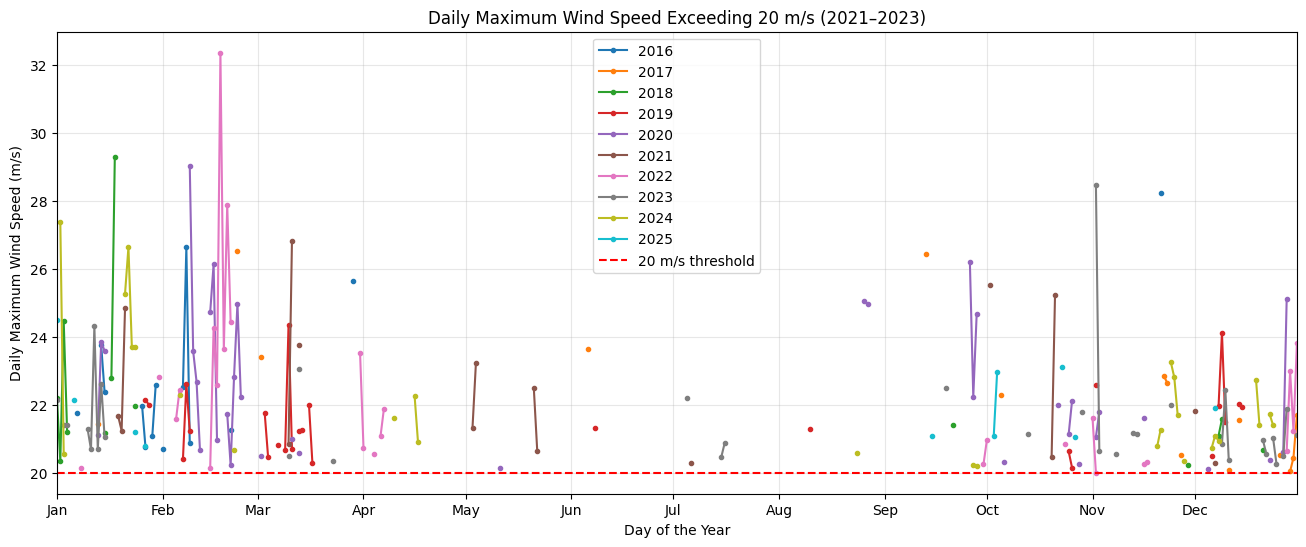

In [ ]:
plt.figure(figsize=(16, 6))

threshold = 20

for year in [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]:

    yearly_data = daily_max_wind[
        daily_max_wind["year"] == year
    ].copy()

    # Hide daily maximum values that do not exceed 20 m/s
    wind_speed = yearly_data["wind_speed_100m"].where(
        yearly_data["wind_speed_100m"] > threshold
    )

    plt.plot(
        yearly_data["day_of_year"],
        wind_speed,
        label=str(year),
        marker="o",
        markersize=3
    )

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="20 m/s threshold"
)

plt.xlabel("Day of the Year")
plt.ylabel("Daily Maximum Wind Speed (m/s)")
plt.title("Daily Maximum Wind Speed Exceeding 20 m/s (2021–2023)")

plt.xticks(
    [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.legend()
plt.grid(alpha=0.3)
plt.xlim(1, 365)
plt.show()

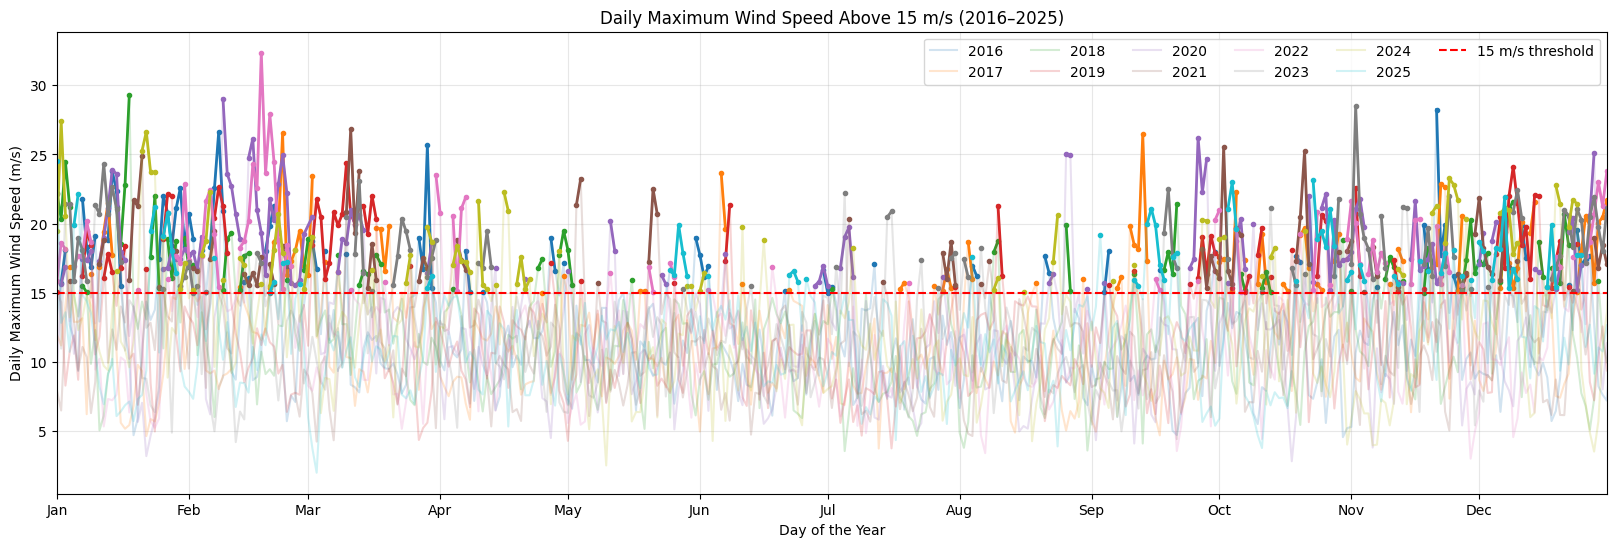

In [ ]:
plt.figure(figsize=(20, 6))

threshold = 15

for year in range(2016, 2026):

    yearly_data = daily_max_wind[
        daily_max_wind["year"] == year
    ].copy()

    x = yearly_data["day_of_year"].to_numpy()
    y = yearly_data["wind_speed_100m"].to_numpy()

    line, = plt.plot(
        x, y,
        alpha=0.2,
        label=f"{year}"
    )

    plt.plot(
        x,
        np.where(y > threshold, y, np.nan),
        color=line.get_color(),
        linewidth=2,
        marker="o",
        markersize=3
    )

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="15 m/s threshold"
)

plt.xlabel("Day of the Year")
plt.ylabel("Daily Maximum Wind Speed (m/s)")
plt.title("Daily Maximum Wind Speed Above 15 m/s (2016–2025)")

plt.xticks(
    [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.legend(ncol=6)
plt.grid(alpha=0.3)
plt.xlim(1, 365)
plt.show()

Based on the multi-year seasonal distribution shown in graph—highlighting heavy-tail clustering of extreme wind events above $15\text{ m/s}$ during winter/spring (Jan–Apr) and late autumn (Nov–Dec) compared to summer suppression—here is a robust, production-grade machine learning strategy to forecast 24-hour wind speeds using the ERA5 single-levels reanalysis dataset

**Graph Observations**   
1) **Extreme Seasonality & Variance**:
- The plot demonstrates that high-wind events ($>15\text{ m/s}$, reaching up to $30\text{ m/s}$) are heavily regime-dependent.   
- A standard global model trained with a uniform mean-squared error (MSE) loss will severely under-forecast these peaks because calm summer days dominate the baseline variance.

**Feature Engineering**

In [ ]:
import numpy as np
import pandas as pd

def build_era5_features(df: pd.DataFrame, lookback_hours: int = 72) -> pd.DataFrame:
    """
    df must contain columns:
    ['u100', 'v100', 'u10', 'v10', 'wind_speed_100m', 'wind_speed_10m',
     't2m', 'd2m', 'msl', 'sp', 'tcc', 'tp'] indexed by datetime.
    """
    df = df.sort_index().copy()

    # 1. Vector Shear & Magnitudes
    df['shear_100_10'] = df['wind_speed_100m'] - df['wind_speed_10m']
    df['vec_shear'] = np.sqrt((df['u100'] - df['u10'])**2 + (df['v100'] - df['v10'])**2)

    # 2. Thermodynamic & Physical Proxies
    R_spec = 287.058  # Specific gas constant for dry air J/(kg·K)
    df['air_density'] = df['sp'] / (R_spec * df['t2m'])
    df['dew_point_depression'] = df['t2m'] - df['d2m']

    # 3. Synoptic Pressure Tendencies
    df['msl_diff_1h'] = df['msl'].diff(1)
    df['msl_diff_3h'] = df['msl'].diff(3)
    df['msl_diff_6h'] = df['msl'].diff(6)

    # 4. Cyclic Time Features
    hour = df.index.hour
    day_of_year = df.index.dayofyear
    df['hour_sin'] = np.sin(2 * np.pi * hour / 24.0)
    df['hour_cos'] = np.cos(2 * np.pi * hour / 24.0)
    df['doy_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
    df['doy_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)

    # 5. Lags and Rolling Window Statistics
    base_cols = [
        'wind_speed_100m', 'shear_100_10', 'msl_diff_3h',
        'air_density', 'u100', 'v100', 'tcc', 'tp'
    ]

    lag_features = {}

    # Historical Lags (1h, 2h, 3h, 6h, 12h, 24h)
    for col in base_cols:
        for lag in [1, 2, 3, 6, 12, 24]:
            lag_features[f'{col}_lag_{lag}h'] = df[col].shift(lag)

    # Rolling Statistics (Mean, Std, Max) over 6h, 12h, and 24h windows
    for col in ['wind_speed_100m', 'msl', 'shear_100_10']:
        for window in [6, 12, 24]:
            lag_features[f'{col}_roll_mean_{window}h'] = df[col].shift(1).rolling(window).mean()
            lag_features[f'{col}_roll_std_{window}h'] = df[col].shift(1).rolling(window).std()
            lag_features[f'{col}_roll_max_{window}h'] = df[col].shift(1).rolling(window).max()

    df_lags = pd.DataFrame(lag_features, index=df.index)
    df_out = pd.concat([df, df_lags], axis=1)

    return df_out

**Asymmetric Custom Loss Function**

In [ ]:
import lightgbm as lgb

def asymmetric_high_wind_loss(y_pred: np.ndarray, dataset: lgb.Dataset, high_wind_threshold: float = 12.0, weight: float = 3.0):
    """
    Custom objective for LightGBM penalizing under-predictions on high wind days.
    """
    y_true = dataset.get_label()
    residual = y_pred - y_true

    # Default gradient and hessian (MSE)
    grad = residual
    hess = np.ones_like(y_pred)

    # Apply asymmetric multiplier if actual > threshold AND prediction < actual
    under_predict_mask = (y_true > high_wind_threshold) & (y_pred < y_true)
    grad[under_predict_mask] *= weight
    hess[under_predict_mask] *= weight

    return grad, hess

**Multi-Horizon Training & Validation Setup**

In [ ]:
def train_24h_direct_models(df_features: pd.DataFrame, target_col: str = 'wind_speed_100m'):
    # Drop rows containing NaNs created by lagging/rolling
    df_clean = df_features.dropna().copy()

    # Construct targets for h = 1 to 24 hours into the future
    target_df = pd.DataFrame({
        f'target_h{h}': df_clean[target_col].shift(-h) for h in range(1, 25)
    }, index=df_clean.index)

    # Combine and drop rows where targets reach beyond the dataset end
    full_df = pd.concat([df_clean, target_df], axis=1).dropna()

    # Feature columns (exclude raw non-lagged targets or future indices)
    feature_cols = [c for c in df_clean.columns if c not in ['target_h' + str(i) for i in range(1, 25)]]

    # Split chronologically (e.g., using date thresholds)
    train_mask = full_df.index < '2024-01-01'
    val_mask = (full_df.index >= '2024-01-01') & (full_df.index < '2025-01-01')

    X_train, X_val = full_df.loc[train_mask, feature_cols], full_df.loc[val_mask, feature_cols]

    models = {}

    params = {
        'boosting_type': 'gbdt',
        'learning_rate': 0.03,
        'num_leaves': 63,
        'feature_fraction': 0.8,
        'bagging_fraction': 0.8,
        'bagging_freq': 1,
        'verbosity': -1
    }

    for h in range(1, 25):
        y_train_h = full_df.loc[train_mask, f'target_h{h}']
        y_val_h = full_df.loc[val_mask, f'target_h{h}']

        dtrain = lgb.Dataset(X_train, label=y_train_h)
        dval = lgb.Dataset(X_val, label=y_val_h, reference=dtrain)

        # Train individual horizon model
        model = lgb.train(
            params,
            dtrain,
            num_boost_round=1000,
            valid_sets=[dtrain, dval],
            fobj=asymmetric_high_wind_loss,
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
        )
        models[f'h_{h}'] = model
        print(f"Horizon t+{h}h model trained successfully.")

    return models

In [ ]:
# Execute Training Workflow
    trained_models, processed_data = run_wind_forecast_pipeline()

    # Example Inference Run
    sample_time = pd.to_datetime("2025-06-01 12:00:00")
    print(f"\nRunning inference for timestamp: {sample_time}")
    forecast_results = predict_next_24h(trained_models, processed_data, sample_time)
    print(forecast_results)

In [ ]:
thresholds = [15, 18, 20, 22, 25]

for threshold in thresholds:
    print(f"\nThreshold: {threshold} m/s")

    print(
        daily_max_wind[
            daily_max_wind["wind_speed_100m"] > threshold
        ].groupby("year").size()
    )


Threshold: 15 m/s
year
2016     79
2017     93
2018     86
2019     85
2020    121
2021     87
2022     86
2023    102
2024     89
2025     75
dtype: int64

Threshold: 18 m/s
year
2016    37
2017    36
2018    30
2019    43
2020    58
2021    33
2022    42
2023    47
2024    48
2025    28
dtype: int64

Threshold: 20 m/s
year
2016    14
2017    15
2018    13
2019    26
2020    36
2021    16
2022    27
2023    34
2024    28
2025    10
dtype: int64

Threshold: 22 m/s
year
2016     7
2017     7
2018     4
2019     8
2020    18
2021     7
2022    11
2023     9
2024    10
2025     4
dtype: int64

Threshold: 25 m/s
year
2016    3
2017    2
2018    1
2020    5
2021    3
2022    2
2023    1
2024    3
dtype: int64


In [ ]:
df["wind_speed_100m"] = np.sqrt(
    df["u100"]**2 + df["v100"]**2
)

df["wind_speed_10m"] = np.sqrt(
    df["u10"]**2 + df["v10"]**2
)

print(
    df[["wind_speed_10m", "wind_speed_100m"]].describe()
)

       wind_speed_10m  wind_speed_100m
count     2160.000000      2160.000000
mean         8.416397        10.397564
std          3.839012         5.121724
min          0.115158         0.080457
25%          5.468813         6.539438
50%          8.273150        10.076128
75%         10.920151        13.732232
max         24.316374        32.364433


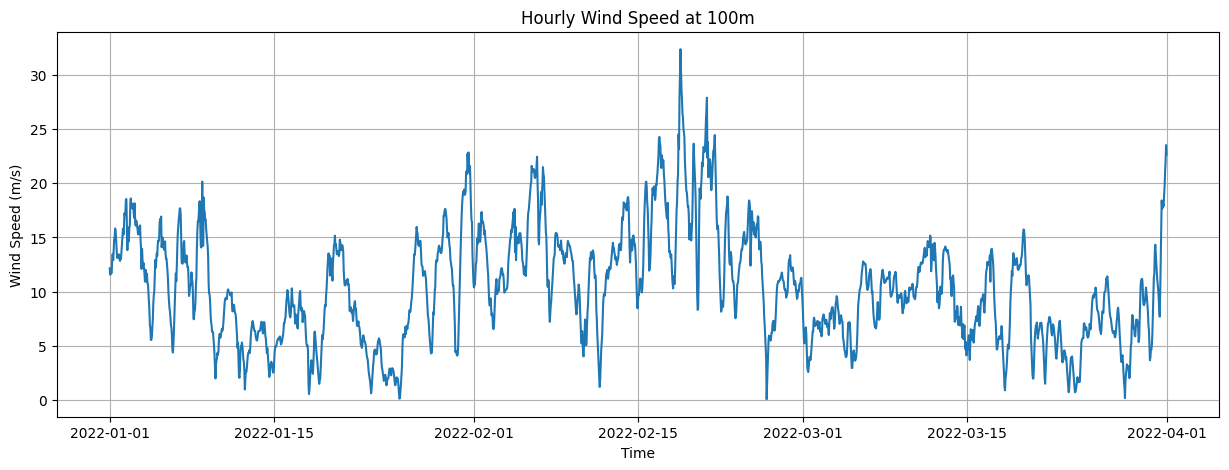

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    df["valid_time"],
    df["wind_speed_100m"]
)

plt.title("Hourly Wind Speed at 100m")
plt.xlabel("Time")
plt.ylabel("Wind Speed (m/s)")
plt.grid()
plt.show()

| Argument | Validation |
| :--- | :--- |
| **Is wind speed relatively stable?** | No |
| **Are there sudden peaks?** | No |
| **Does it increase and decrease gradually?** | Yes |
| **Are there any unusual observations?** | Yes |


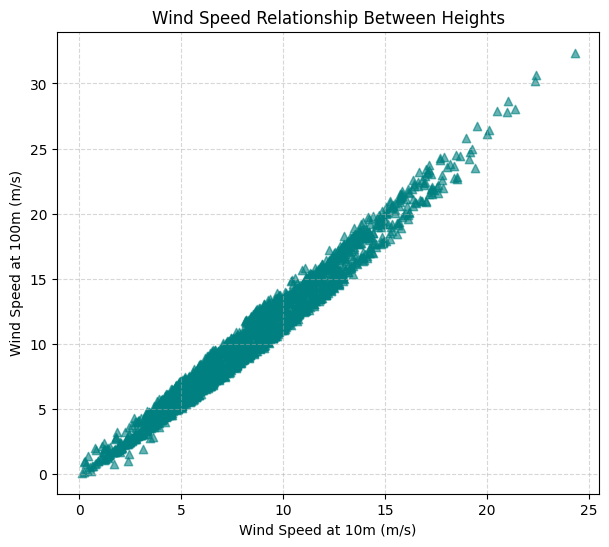

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(
    df["wind_speed_10m"],
    df["wind_speed_100m"],
    alpha=0.6,
    color="teal",       # Change color (e.g., "dodgerblue", "crimson", "#00B5E2")
    marker="^"          # Change marker shape (e.g., "^" for triangles, "s" for squares, "x" for crosses)
)

plt.xlabel("Wind Speed at 10m (m/s)")
plt.ylabel("Wind Speed at 100m (m/s)")
plt.title("Wind Speed Relationship Between Heights")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [ ]:
df["t2m_celsius"] = df["t2m"] - 273.15

df["d2m_celsius"] = df["d2m"] - 273.15

df["msl_hpa"] = df["msl"] / 100

df["sp_hpa"] = df["sp"] / 100

| Attribute | Details |
| :--- | :--- |
| **Observation Result** | 744 |
| **Number of observations** | 744 |
| **Time resolution** | Hourly |
| **Variables** | 10 weather variables |
| **Missing values** | None |
| **Location** | 51.75° N, 3.0° E |
| **Period** | January 2020 |
| **Data types** | float32, float64, datetime64 |

**Pearson Correlation**

It measures the strength and direction of a linear relationship between two variables


$-1 <= r <= 1$

- $r \approx 1$: Strong positive linear relationship.
- $r \approx -1$: Strong negative linear relationship.
- $r \approx 0$: Little or no linear relationship.

In [ ]:
print(
    "Average 100m wind speed:",
    df["wind_speed_100m"].mean()
)

print(
    "Average 10m wind speed:",
    df["wind_speed_10m"].mean()
)

print(
    "Correlation:",
    df["wind_speed_10m"].corr(
        df["wind_speed_100m"]
    )
)

Average 100m wind speed: 10.397564
Average 10m wind speed: 8.416397
Correlation: 0.9863004069408753


**Investigate temporal behaviour**

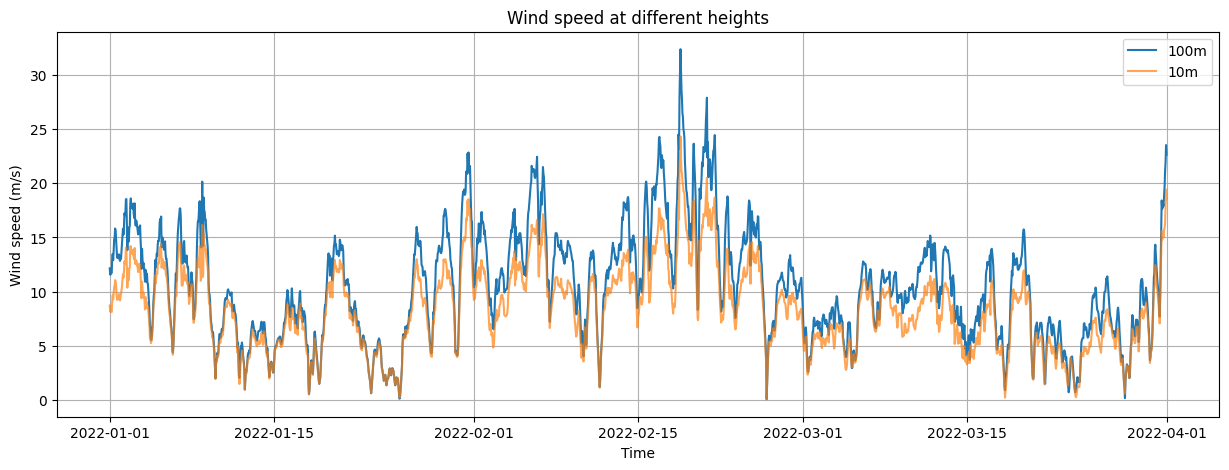

In [ ]:
plt.figure(figsize=(15, 5))

plt.plot(
    df["valid_time"],
    df["wind_speed_100m"],
    label="100m",
)

plt.plot(
    df["valid_time"],
    df["wind_speed_10m"],
    label="10m",
    alpha=0.7
)

plt.xlabel("Time")
plt.ylabel("Wind speed (m/s)")
plt.title("Wind speed at different heights")
plt.legend()
plt.grid()
plt.show()

| Argument | Validation |
| :--- | :--- |
| **Do both wind speeds generally increase and decrease together?** | Yes |
| **Are there periods when wind speed changes rapidly?** | Yes |
| **Does the 100 m wind speed consistently remain higher than the 10 m wind speed?** | Yes |


- Autocorrelation.
- Lag features.
- Rolling averages.
- Correlation between atmospheric variables.
- Whether the data exhibits trends or seasonal patterns.

**Autocorrelation**

Trying to find the autocorrelation of lags.  
**lag features** are useful to learn historical behaviour

In [ ]:
lags = [1, 2, 3, 6, 12, 24, 48, 72, 168]

for lag in lags:
    correlation = df["wind_speed_100m"].corr(
        df["wind_speed_100m"].shift(lag)
    )

    print(f"Lag {lag}: {correlation:.4f}")

Lag 1: 0.9851
Lag 2: 0.9597
Lag 3: 0.9285
Lag 6: 0.8236
Lag 12: 0.6394
Lag 24: 0.4539
Lag 48: 0.4525
Lag 72: 0.3579
Lag 168: 0.1066


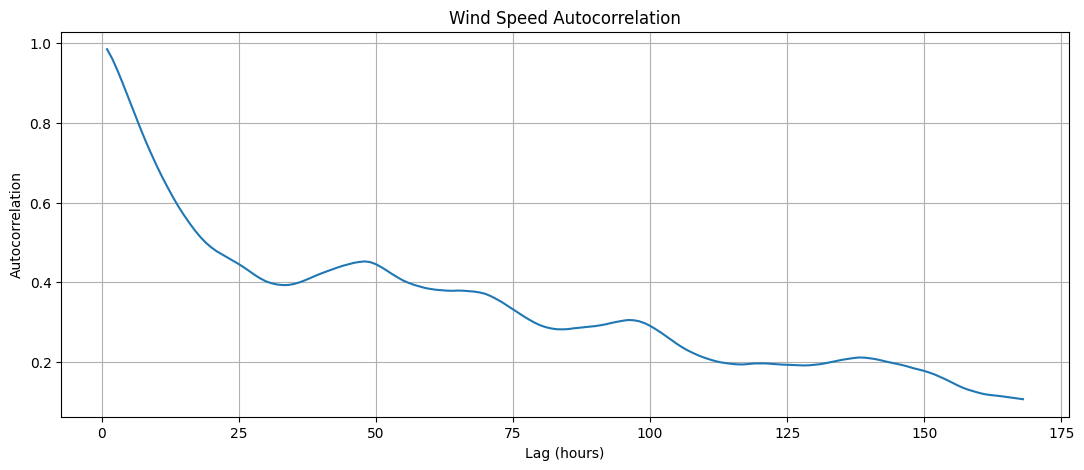

In [ ]:
import matplotlib.pyplot as plt

lags = range(1, 169)

autocorrelations = [
    df["wind_speed_100m"].corr(
        df["wind_speed_100m"].shift(lag)
    )
    for lag in lags
]

plt.figure(figsize=(13, 5))

plt.plot(lags, autocorrelations)

plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.title("Wind Speed Autocorrelation")
plt.grid()

plt.show()

**Observation:**  
wind speed has strong short-term temporal dependence, but the relationship becomes weaker as we look further into the past.

**Conclusion**  
data contains temporal information. The previous wind speed can help us estimate the next wind speed.

**lag features** can be used for wind forecasting


###Next investigation: Does wind speed have a daily pattern?

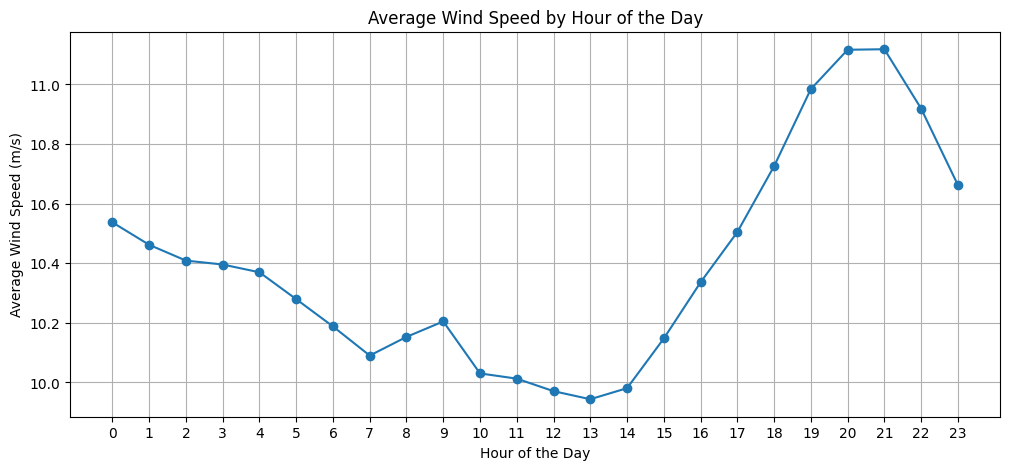

In [ ]:
df["hour"] = df["valid_time"].dt.hour

hourly_pattern = df.groupby("hour")["wind_speed_100m"].mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly_pattern.index, hourly_pattern.values, marker="o")

plt.xlabel("Hour of the Day")
plt.ylabel("Average Wind Speed (m/s)")
plt.title("Average Wind Speed by Hour of the Day")

plt.xticks(range(24))
plt.grid()
plt.show()

| Argument | Validation |
| :--- | :--- |
| **Is wind speed generally higher during the night?** | 744 |
| **Does it decrease during the afternoon?** | 744 |
| **Is there a recurring 24-hour pattern?** | Hourly |











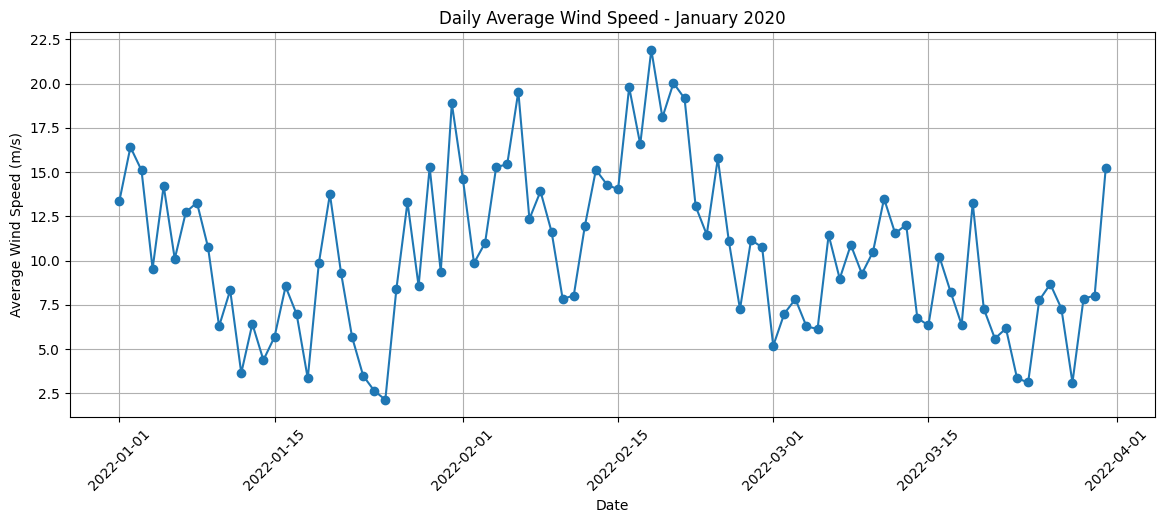

In [ ]:
df["date"] = df["valid_time"].dt.date

daily_wind_speed = (
    df.groupby("date")["wind_speed_100m"]
    .mean()
)

plt.figure(figsize=(14, 5))
plt.plot(daily_wind_speed.index, daily_wind_speed.values, marker="o")

plt.xlabel("Date")
plt.ylabel("Average Wind Speed (m/s)")
plt.title("Daily Average Wind Speed - January 2020")
plt.xticks(rotation=45)
plt.grid()
plt.show()

In [ ]:
print(daily_wind_speed.describe())

count    90.000000
mean     10.397565
std       4.516929
min       2.133718
25%       7.067091
50%       9.975987
75%      13.465538
max      21.913908
Name: wind_speed_100m, dtype: float64


**This suggests that recent weather observations could be more informative than time-based features alone**

In [ ]:
print(df["wind_speed_100m"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
))

0.50    10.076128
0.75    13.732232
0.90    17.171707
0.95    19.644694
0.99    23.596446
Name: wind_speed_100m, dtype: float64


In [ ]:
threshold = df["wind_speed_100m"].quantile(0.95)

high_wind = df[df["wind_speed_100m"] >= threshold]

print("95th percentile threshold:", threshold)
print("Number of high-wind observations:", len(high_wind))
print(high_wind[["valid_time", "wind_speed_100m"]])

95th percentile threshold: 19.644694328308088
Number of high-wind observations: 108
              valid_time  wind_speed_100m
189  2022-01-08 21:00:00        20.147444
728  2022-01-31 08:00:00        21.075195
729  2022-01-31 09:00:00        20.822884
730  2022-01-31 10:00:00        20.939116
731  2022-01-31 11:00:00        22.747721
...                  ...              ...
2155 2022-03-31 19:00:00        19.708748
2156 2022-03-31 20:00:00        21.103300
2157 2022-03-31 21:00:00        21.989944
2158 2022-03-31 22:00:00        23.521685
2159 2022-03-31 23:00:00        22.642912

[108 rows x 2 columns]


What if we take data like this and compare the pattern for each month,   
2020 Jan Feb Mar Apr May Jun Jul Aug Sep Aug    
2021 Jan Feb Mar Apr May Jun Jul Aug Sep Aug  
2022 Jan Feb Mar Apr May Jun Jul Aug Sep Aug  

In [ ]:
import pandas as pd
import numpy as np

# 1. Ensure df26 features are ready (if not already run)
if 'df26_features' not in locals():
    time_col = 'time' if 'time' in df26.columns else 'valid_time'
    if time_col in df26.columns and not isinstance(df26.index, pd.DatetimeIndex):
        df26[time_col] = pd.to_datetime(df26[time_col])
        df26 = df26.set_index(time_col)
    df26 = df26.sort_index()
    df26_features = build_era5_features(df26)

# 2. Find the highest wind speed event in March 2026 (> 15 m/s)
target_col = 'wind_speed_100m'
storm_mask = df26[target_col] > 15.0

if storm_mask.sum() == 0:
    print("No extreme wind events (> 15 m/s) found in this March dataset. Lowering threshold to > 12 m/s...")
    storm_mask = df26[target_col] > 12.0

# Pick the first major storm timestamp found in March
storm_timestamps = df26[storm_mask].index

if len(storm_timestamps) > 0:
    selected_storm_time = storm_timestamps[0]
    print(f"\n Found high-wind storm event at: {selected_storm_time}")
    print(f"   Actual peak wind speed at this hour: {df26.loc[selected_storm_time, target_col]:.2f} m/s")

    # 3. Generate the 24h forecast and get actuals
    forecast_series = predict_from_df(str(selected_storm_time), df26_features)
    actual_series = get_actuals_from_df(str(selected_storm_time), df26)

    storm_comparison = pd.DataFrame({
        'Predicted (m/s)': forecast_series.values,
        'Actual (m/s)': actual_series.values
    }, index=forecast_series.index)

    storm_comparison['Error (Pred - Act)'] = storm_comparison['Predicted (m/s)'] - storm_comparison['Actual (m/s)']

    print("\n--- 24-Hour Storm Evolution Comparison ---")
    print(storm_comparison.to_string())

    # Quick metrics for this specific storm forecast
    rmse_storm = np.sqrt(np.mean((storm_comparison['Predicted (m/s)'] - storm_comparison['Actual (m/s)'])**2))
    bias_storm = storm_comparison['Error (Pred - Act)'].mean()
    print(f"\nStorm Forecast Summary -> RMSE: {rmse_storm:.2f} m/s | Mean Bias: {bias_storm:.2f} m/s")
else:
    print("No significant wind spikes found in the dataset.")


 Found high-wind storm event at: 2026-03-01 15:00:00
   Actual peak wind speed at this hour: 15.22 m/s

--- 24-Hour Storm Evolution Comparison ---
                     Predicted (m/s)  Actual (m/s)  Error (Pred - Act)
2026-03-01 16:00:00        15.472033     15.277760            0.194273
2026-03-01 17:00:00        15.119071     14.939318            0.179754
2026-03-01 18:00:00        15.460755     14.585876            0.874879
2026-03-01 19:00:00        15.144475     14.038822            1.105653
2026-03-01 20:00:00        14.771779     13.458211            1.313568
2026-03-01 21:00:00        15.124012     13.146116            1.977896
2026-03-01 22:00:00        14.901002     13.352386            1.548616
2026-03-01 23:00:00        14.824816     12.330059            2.494757
2026-03-02 00:00:00        14.314434     11.775305            2.539129
2026-03-02 01:00:00        14.263416     11.723342            2.540074
2026-03-02 02:00:00        14.141800     11.823944            2.317856


In [ ]:
import pandas as pd
import numpy as np

# 1. Select the target storm peak timestamp on Feb 18, 2022
# (Let's check 12:00 UTC, a common peak window for European windstorms)
target_storm_time = '2022-02-18 12:00:00'

# Ensure your dataframe has datetime index set
# (Assuming your historical dataset is loaded as `df`)
time_col = 'time' if 'time' in df.columns else 'valid_time'
if time_col in df.columns and not isinstance(df.index, pd.DatetimeIndex):
    df[time_col] = pd.to_datetime(df[time_col])
    df = df.set_index(time_col)
df = df.sort_index()

# 2. Verify if the date exists in your dataset
if pd.to_datetime(target_storm_time) in df.index:
    actual_peak = df.loc[target_storm_time, 'wind_speed_100m']
    print(f"--- Checking Storm Eunice / Feb 18 Event ---")
    print(f"Selected Timestamp: {target_storm_time}")
    print(f"Recorded Actual Wind Speed at 100m: {actual_peak:.2f} m/s")

    # 3. Generate 24h forecast and actuals comparison
    forecast_series = predict_from_df(target_storm_time, df_features) # using your feature df
    actual_series = get_actuals_from_df(target_storm_time, df)

    feb_comparison = pd.DataFrame({
        'Predicted (m/s)': forecast_series.values,
        'Actual (m/s)': actual_series.values
    }, index=forecast_series.index)

    feb_comparison['Error (Pred - Act)'] = feb_comparison['Predicted (m/s)'] - feb_comparison['Actual (m/s)']

    print("\n--- 24-Hour Evolution Comparison (Feb 18, 2022) ---")
    print(feb_comparison.to_string())

    # Summary metrics for this major event
    rmse_event = np.sqrt(np.mean((feb_comparison['Predicted (m/s)'] - feb_comparison['Actual (m/s)'])**2))
    bias_event = feb_comparison['Error (Pred - Act)'].mean()
    print(f"\nStorm Performance Summary -> RMSE: {rmse_event:.2f} m/s | Mean Bias: {bias_event:.2f} m/s")
else:
    print(f"Timestamp {target_storm_time} is outside the date range of your currently loaded dataset. Check if your historical training/test set covers early 2022.")

--- Checking Storm Eunice / Feb 18 Event ---
Selected Timestamp: 2022-02-18 12:00:00
Recorded Actual Wind Speed at 100m: 28.05 m/s

--- 24-Hour Evolution Comparison (Feb 18, 2022) ---
                     Predicted (m/s)  Actual (m/s)  Error (Pred - Act)
2022-02-18 13:00:00        30.214384     30.204149            0.010234
2022-02-18 14:00:00        31.510886     32.364433           -0.853547
2022-02-18 15:00:00        30.350445     30.643316           -0.292872
2022-02-18 16:00:00        28.956115     28.642208            0.313907
2022-02-18 17:00:00        27.606269     27.810459           -0.204190
2022-02-18 18:00:00        23.160479     26.457058           -3.296579
2022-02-18 19:00:00        22.289189     26.087368           -3.798179
2022-02-18 20:00:00        21.178773     24.998116           -3.819343
2022-02-18 21:00:00        20.344762     24.704683           -4.359921
2022-02-18 22:00:00        19.577998     24.197895           -4.619897
2022-02-18 23:00:00        18.65160

In [ ]:
import pandas as pd

# 1. Load your dataset
df = pd.read_csv('df25.csv')

# 2. Convert and set datetime index (adjust column name if yours is 'valid_time' or 'time')
time_col = 'valid_time' if 'valid_time' in df.columns else 'time'
df[time_col] = pd.to_datetime(df[time_col])
df = df.set_index(time_col).sort_index()

# 3. Ensure scalar wind speed 100m is calculated if not already present
if 'wind_speed_100m' not in df.columns and 'u100' in df.columns and 'v100' in df.columns:
    df['wind_speed_100m'] = (df['u100']**2 + df['v100']**2)**0.5

# 4. Filter for January to June 2026 where wind speed > 15 m/s
jan_jun_2026 = df.loc['2025-01-01':'2025-12-31']
high_winds = jan_jun_2026[jan_jun_2026['wind_speed_100m'] > 23.0]

print(f"Total storm/high-wind hours found: {len(high_winds)}")
print("\nSample of high-wind timestamps and speeds:")
print(high_winds[['wind_speed_100m']].head(10))

# Optional: Export the filtered events to a new CSV file
high_winds[['wind_speed_100m']].to_csv('borssele_high_wind_events_2026.csv')

Total storm/high-wind hours found: 8

Sample of high-wind timestamps and speeds:
                     wind_speed_100m
valid_time                          
2025-01-01 08:00:00        23.602210
2025-01-01 09:00:00        23.825986
2025-01-01 10:00:00        23.680966
2025-01-01 11:00:00        24.205629
2025-01-01 12:00:00        24.381611
2025-01-01 13:00:00        24.515067
2025-01-01 14:00:00        23.905897
2025-10-23 14:00:00        23.118388


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 6))

threshold = 15

for year in range(2025):

    yearly_data = daily_max_wind[
        daily_max_wind["year"] == year
    ].copy()

    x = yearly_data["day_of_year"].to_numpy()
    y = yearly_data["wind_speed_100m"].to_numpy()

    line, = plt.plot(
        x, y,
        alpha=0.2,
        label=f"{year}"
    )

    plt.plot(
        x,
        np.where(y > threshold, y, np.nan),
        color=line.get_color(),
        linewidth=2,
        marker="o",
        markersize=3
    )

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="15 m/s threshold"
)

plt.xlabel("Day of the Year")
plt.ylabel("Daily Maximum Wind Speed (m/s)")
plt.title("Daily Maximum Wind Speed Above 15 m/s (2016–2025)")

plt.xticks(
    [1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335],
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.legend(ncol=6)
plt.grid(alpha=0.3)
plt.xlim(1, 365)
plt.show()

NameError: name 'daily_max_wind' is not defined

<Figure size 2000x600 with 0 Axes>